# Day 6: Tuning, 3-model ensemble, FINAL test (once), and error analysis
Needs Days 1-5b. Only ONE thing to edit: the BASE address in the first code cell.
Tuning and the ensemble use the VALIDATION set. The TEST set is touched only once, in cell 7.

In [1]:

BASE = r"C:\Users\Abdul Rehman\Documents\Projects\emotion-recognition"  

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
import IPython.display as ipd

BASE = Path(BASE)
EPOCHS = 60
N_CONFIGS = 3         
N_ENSEMBLE = 3        

improve = json.load(open(BASE / "models" / "improve_config.json"))   # written by Day 5b
USE_CMN, USE_MASK = improve["use_cmn"], improve["use_mask"]
print("Setup from Day 5b -> per-clip normalisation:", USE_CMN, "| masking:", USE_MASK)

df = pd.read_csv(BASE / "data" / "metadata.csv")
lookup = {f.name: str(f) for f in (BASE / "data" / "ravdess").rglob("*.wav")}
df["path"] = df["path"].map(lambda p: lookup.get(Path(p).name))

X = np.load(BASE / "features" / "X_mfcc.npy")
y = np.load(BASE / "features" / "y.npy")
X_aug = np.load(BASE / "features" / "X_aug.npy")
y_aug = np.load(BASE / "features" / "y_aug.npy")
classes = json.load(open(BASE / "models" / "classes.json"))

tr = (df["actor"] <= 16).values
va = df["actor"].between(17, 20).values
te = (df["actor"] >= 21).values

Setup from Day 5b -> per-clip normalisation: True | masking: False


In [2]:

def cmn(x):                                              
    valid = np.any(x != 0, axis=0)
    if valid.sum() < 2:
        valid[:] = True
    out = x.copy()
    out[1:, valid] = x[1:, valid] - x[1:, valid].mean(axis=1, keepdims=True)
    return out.astype(np.float32)

NORM_FILE = "norm_cmn.npz" if USE_CMN else "norm.npz"
norm = np.load(BASE / "models" / NORM_FILE)
mean, std = norm["mean"], norm["std"]                    # each (40, 1)

def prep(A):
    if USE_CMN:
        A = np.stack([cmn(a) for a in A])
    return ((A - mean) / std)[..., np.newaxis].astype(np.float32)

Xtr = prep(np.concatenate([X[tr], X_aug]))
y_train = np.concatenate([y[tr], y_aug])
Xva, Xte = prep(X[va]), prep(X[te])
print("Input shapes (train / validation / test):", Xtr.shape, Xva.shape, Xte.shape)   # train should start with 3840

cw_arr = compute_class_weight("balanced", classes=np.arange(8), y=y_train)

Input shapes (train / validation / test): (3840, 40, 130, 1) (240, 40, 130, 1) (240, 40, 130, 1)


In [3]:
# Model, masking, and training helper
def build_cnn(lr=1e-3, dropout=0.4, width=32):
    m = models.Sequential([
        layers.Input(shape=(40, 130, 1)),
        layers.Conv2D(width, 3, padding="same", activation="relu"), layers.BatchNormalization(momentum=0.9), layers.MaxPooling2D(2),
        layers.Conv2D(width * 2, 3, padding="same", activation="relu"), layers.BatchNormalization(momentum=0.9), layers.MaxPooling2D(2),
        layers.Conv2D(width * 4, 3, padding="same", activation="relu"), layers.BatchNormalization(momentum=0.9), layers.GlobalAveragePooling2D(),
        layers.Dropout(dropout), layers.Dense(64, activation="relu"), layers.Dense(8, activation="softmax")])
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def rand_band(max_w, axis_len, b):
    w = tf.random.uniform([b], 0, max_w + 1, dtype=tf.int32)
    start = tf.cast(tf.random.uniform([b]) * tf.cast(axis_len - w + 1, tf.float32), tf.int32)
    idx = tf.range(axis_len)[tf.newaxis, :]
    return (idx >= start[:, tf.newaxis]) & (idx < (start + w)[:, tf.newaxis])

def spec_mask(x, y_, sw, max_time=20, max_freq=6):
    shp = tf.shape(x)
    b, f, t = shp[0], shp[1], shp[2]
    time_m, freq_m = rand_band(max_time, t, b), rand_band(max_freq, f, b)
    mask = freq_m[:, :, tf.newaxis, tf.newaxis] | time_m[:, tf.newaxis, :, tf.newaxis]
    return tf.where(mask, tf.zeros_like(x), x), y_, sw

def make_train_ds(seed, batch=32):
    cw_t = tf.constant(cw_arr, dtype=tf.float32)
    ds = tf.data.Dataset.from_tensor_slices((Xtr, y_train))
    ds = ds.shuffle(len(Xtr), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(lambda a, b_: (a, b_, tf.gather(cw_t, b_)))
    ds = ds.batch(batch)
    if USE_MASK:
        ds = ds.map(spec_mask)
    return ds.prefetch(1)

def get_callbacks():
    return [tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=20, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="loss", factor=0.5, patience=5, min_lr=1e-5)]

def train_one(cfg, seed):
    tf.keras.utils.set_random_seed(seed)
    m = build_cnn(**cfg)
    m.fit(make_train_ds(seed), validation_data=(Xva, y[va]), epochs=EPOCHS, callbacks=get_callbacks(), verbose=0)
    return m

def scores(probs, labels):
    pred = probs.argmax(axis=1)
    return accuracy_score(labels, pred), f1_score(labels, pred, average="macro")

In [4]:
#  Tuning a few settings on the VALIDATION set 
configs = [
    dict(lr=1e-3, dropout=0.4, width=32),
    dict(lr=5e-4, dropout=0.4, width=32),
    dict(lr=1e-3, dropout=0.5, width=32),
    dict(lr=1e-3, dropout=0.3, width=64),
    dict(lr=5e-4, dropout=0.5, width=64),
    dict(lr=2e-3, dropout=0.4, width=32),
]
configs = configs[:N_CONFIGS]

tuning, best_f1, best_cfg = [], -1.0, None
tmp_path = BASE / "models" / "best_tmp.keras"

for k, cfg in enumerate(configs, 1):
    m = train_one(cfg, seed=42)
    acc, f1 = scores(m.predict(Xva, verbose=0), y[va])
    tuning.append({**cfg, "val_accuracy": round(acc, 4), "val_macro_f1": round(f1, 4)})
    print(f"[{k}/{len(configs)}] {cfg} -> accuracy {acc:.3f}, macro-F1 {f1:.3f}")
    if f1 > best_f1:
        best_f1, best_cfg = f1, cfg
        m.save(tmp_path)

pd.DataFrame(tuning).to_csv(BASE / "results_tuning.csv", index=False)
print("\nBest settings:", best_cfg, "| validation macro-F1:", round(best_f1, 3))
pd.DataFrame(tuning)

c:\Users\Abdul Rehman\Documents\Projects\emotion-recognition\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


[1/3] {'lr': 0.001, 'dropout': 0.4, 'width': 32} -> accuracy 0.671, macro-F1 0.665


c:\Users\Abdul Rehman\Documents\Projects\emotion-recognition\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


[2/3] {'lr': 0.0005, 'dropout': 0.4, 'width': 32} -> accuracy 0.654, macro-F1 0.637


c:\Users\Abdul Rehman\Documents\Projects\emotion-recognition\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


[3/3] {'lr': 0.001, 'dropout': 0.5, 'width': 32} -> accuracy 0.658, macro-F1 0.656

Best settings: {'lr': 0.001, 'dropout': 0.4, 'width': 32} | validation macro-F1: 0.665


,lr,dropout,width,val_accuracy,val_macro_f1
0,0.0010,0.4,32,0.6708,0.6645
1,0.0005,0.4,32,0.6542,0.6367
2,0.0010,0.5,32,0.6583,0.6558


In [5]:

members = [tf.keras.models.load_model(tmp_path)]
for seed in range(43, 43 + N_ENSEMBLE - 1):
    print(f"Training ensemble member with seed {seed} ...")
    members.append(train_one(best_cfg, seed=seed))

val_probs = [m.predict(Xva, verbose=0) for m in members]
single_acc, single_f1 = scores(val_probs[0], y[va])
ens_acc, ens_f1 = scores(np.mean(val_probs, axis=0), y[va])
print(f"Best single model : accuracy {single_acc:.3f} | macro-F1 {single_f1:.3f}")
print(f"Ensemble of {len(members)}      : accuracy {ens_acc:.3f} | macro-F1 {ens_f1:.3f}")

if ens_f1 >= single_f1:
    final_models = members
    print("-> Using the ENSEMBLE.")
else:
    final_models = members[:1]
    print("-> The single model was better on validation, so using the single model.")

Training ensemble member with seed 43 ...


c:\Users\Abdul Rehman\Documents\Projects\emotion-recognition\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Training ensemble member with seed 44 ...
Best single model : accuracy 0.671 | macro-F1 0.665
Ensemble of 3      : accuracy 0.696 | macro-F1 0.691
-> Using the ENSEMBLE.


In [6]:
# Saving the final model(s) and the configuration the app needs
model_files = []
for i, m in enumerate(final_models, 1):
    fname = f"final_{i}.keras"
    m.save(BASE / "models" / fname)
    model_files.append(fname)
tmp_path.unlink(missing_ok=True)

json.dump({"kind": "cnn", "use_cmn": USE_CMN, "use_mask": USE_MASK, "norm_file": NORM_FILE,
           "model_files": model_files, "config": best_cfg},
          open(BASE / "models" / "final_config.json", "w"))
print("Saved:", model_files, "+ models/final_config.json")

Saved: ['final_1.keras', 'final_2.keras', 'final_3.keras'] + models/final_config.json


TEST accuracy: 0.637 | TEST macro-F1: 0.616 | chance: 0.125
              precision    recall  f1-score   support

       angry       0.71      0.84      0.77        32
        calm       0.62      0.94      0.75        32
     disgust       0.55      0.69      0.61        32
     fearful       0.92      0.38      0.53        32
       happy       0.46      0.41      0.43        32
     neutral       0.79      0.69      0.73        16
         sad       0.43      0.19      0.26        32
   surprised       0.71      1.00      0.83        32

    accuracy                           0.64       240
   macro avg       0.65      0.64      0.62       240
weighted avg       0.64      0.64      0.61       240



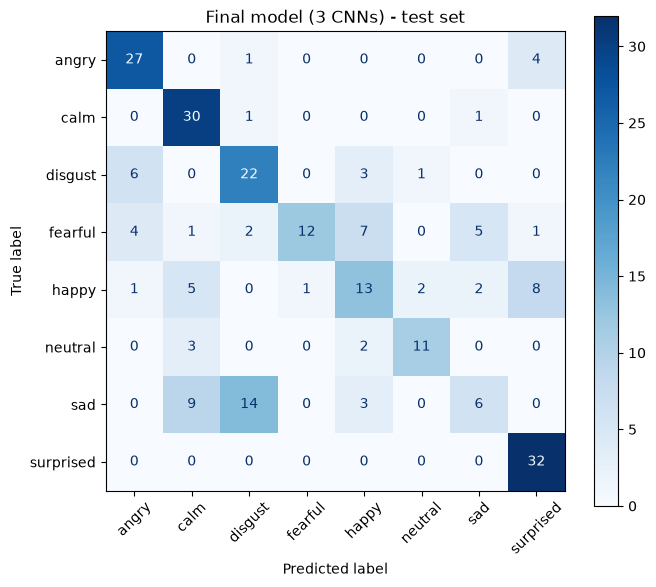

In [7]:
#  FINAL TEST on actors 21-24.
probs = np.mean([m.predict(Xte, verbose=0) for m in final_models], axis=0)
test_pred = probs.argmax(axis=1)
test_acc = accuracy_score(y[te], test_pred)
test_f1 = f1_score(y[te], test_pred, average="macro")

print(f"TEST accuracy: {test_acc:.3f} | TEST macro-F1: {test_f1:.3f} | chance: {1/8:.3f}")
print(classification_report(y[te], test_pred, target_names=classes, zero_division=0))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y[te], test_pred, display_labels=classes,
                                        xticks_rotation=45, cmap="Blues", ax=ax)
plt.title(f"Final model ({len(final_models)} CNN{'s' if len(final_models) > 1 else ''}) - test set")
plt.tight_layout()
plt.show()

json.dump({"models": len(final_models), "use_cmn": USE_CMN, "use_mask": USE_MASK, "config": best_cfg,
           "val_accuracy": round(ens_acc if len(final_models) > 1 else single_acc, 4),
           "test_accuracy": round(test_acc, 4), "test_macro_f1": round(test_f1, 4)},
          open(BASE / "models" / "final_metrics.json", "w"))
# Sanity check: test accuracy far above validation (or above 90%) means a leak. Check your split.

In [8]:
# Error analysis: gender, emotion, and the clips the model got wrong
te_df = df[te].copy().reset_index(drop=True)
te_df["true"] = [classes[i] for i in y[te]]
te_df["pred"] = [classes[i] for i in test_pred]
te_df["confidence"] = probs.max(axis=1).round(3)
te_df["correct"] = te_df["true"] == te_df["pred"]

print("Accuracy by gender:")
print(te_df.groupby("gender")["correct"].mean().round(3))
print("\nAccuracy by emotion:")
print(te_df.groupby("true")["correct"].mean().round(3).sort_values())

print("\nWhat each true emotion was predicted as:")
print(pd.crosstab(te_df["true"], te_df["pred"]))

wrong = te_df[~te_df["correct"]].sort_values("confidence", ascending=False)
print(f"\nMisclassified clips: {len(wrong)} of {len(te_df)}")
wrong[["true", "pred", "confidence", "actor", "path"]].head(10)

Accuracy by gender:
gender
female    0.700
male      0.575
Name: correct, dtype: float64

Accuracy by emotion:
true
sad          0.188
fearful      0.375
happy        0.406
disgust      0.688
neutral      0.688
angry        0.844
calm         0.938
surprised    1.000
Name: correct, dtype: float64

What each true emotion was predicted as:
pred       angry  calm  disgust  fearful  happy  neutral  sad  surprised
true                                                                    
angry         27     0        1        0      0        0    0          4
calm           0    30        1        0      0        0    1          0
disgust        6     0       22        0      3        1    0          0
fearful        4     1        2       12      7        0    5          1
happy          1     5        0        1     13        2    2          8
neutral        0     3        0        0      2       11    0          0
sad            0     9       14        0      3        0    6          0
sur

,true,pred,confidence,actor,path
121,angry,surprised,1.000,23,C:\Users\Abdul Rehman\Documents\Projects\emoti...
122,angry,surprised,1.000,23,C:\Users\Abdul Rehman\Documents\Projects\emoti...
123,angry,surprised,0.999,23,C:\Users\Abdul Rehman\Documents\Projects\emoti...
168,sad,disgust,0.998,23,C:\Users\Abdul Rehman\Documents\Projects\emoti...
153,happy,surprised,0.997,23,C:\Users\Abdul Rehman\Documents\Projects\emoti...
31,fearful,angry,0.995,21,C:\Users\Abdul Rehman\Documents\Projects\emoti...
158,happy,surprised,0.994,23,C:\Users\Abdul Rehman\Documents\Projects\emoti...
30,fearful,angry,0.988,21,C:\Users\Abdul Rehman\Documents\Projects\emoti...
157,happy,surprised,0.988,23,C:\Users\Abdul Rehman\Documents\Projects\emoti...
227,sad,calm,0.986,24,C:\Users\Abdul Rehman\Documents\Projects\emoti...


In [9]:

for _, r in wrong.head(3).iterrows():
    print(f"True: {r['true']} | Predicted: {r['pred']} | Confidence: {r['confidence']}")
    ipd.display(ipd.Audio(r["path"]))

True: angry | Predicted: surprised | Confidence: 1.0


True: angry | Predicted: surprised | Confidence: 1.0


True: angry | Predicted: surprised | Confidence: 0.9990000128746033
